In [1]:
import sys

from IPython.display import display

sys.path.append("..")
from pathlib import Path

import rasterio
from rasterio.plot import show
import duckdb
import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from scipy.spatial.distance import pdist
import pyogrio

from utils.config_loader import load_config

config = load_config("params.yaml")
clean_gpkg = f"../{config['paths']['clean_gpkg']}"
sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 150

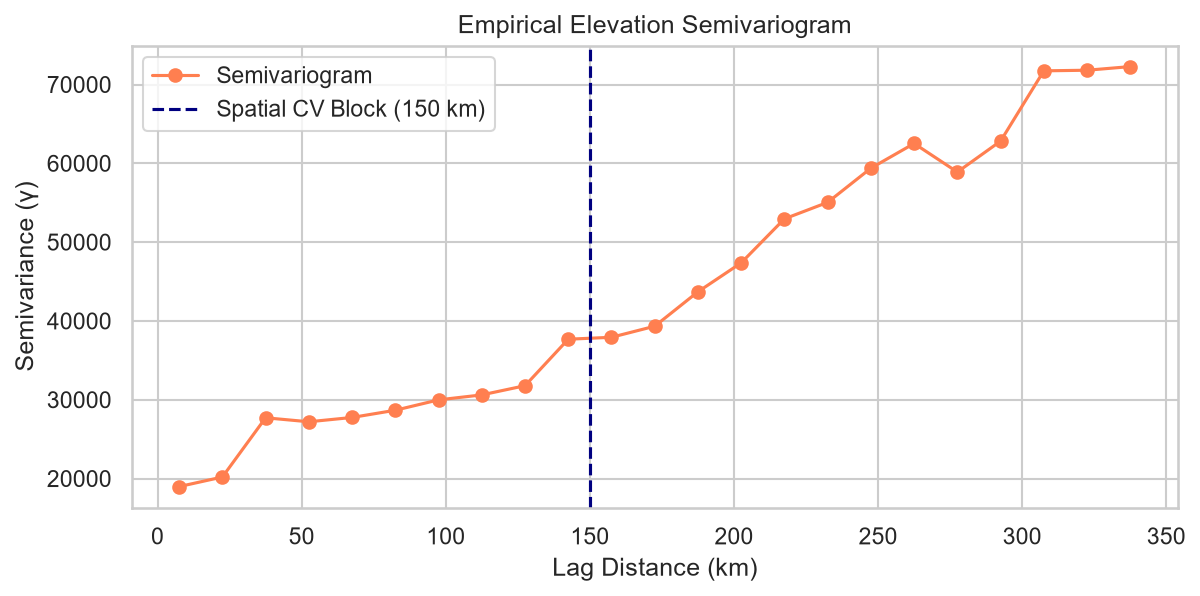

In [6]:
df_feat = pd.read_parquet("../data/02_processed/features_advanced.parquet")
pts = df_feat[(df_feat["target"] == 1) & (df_feat["elevation"] > 0)]

gdf = gpd.GeoDataFrame(
    pts,
    geometry=gpd.points_from_xy(pts.lon, pts.lat),
    crs="EPSG:4326",
).to_crs("EPSG:3035")

sample = gdf.sample(min(2000, len(gdf)), random_state=42)
coords = np.column_stack([sample.geometry.x, sample.geometry.y]) / 1000
vals = sample["elevation"].to_numpy()

dist = pdist(coords)
gamma = (pdist(vals[:, None]) ** 2) / 2

bins = np.arange(0, 350, 15)
bin_labels = (bins[:-1] + bins[1:]) / 2
vario = pd.DataFrame({"dist": dist, "gamma": gamma})
vario["bin"] = pd.cut(vario["dist"], bins=bins, labels=bin_labels)
res = vario.groupby("bin", observed=True)["gamma"].mean()

plt.figure(figsize=(9, 4))
plt.plot(res.index.astype(float), res.values, "o-", color="coral", label="Semivariogram")
plt.axvline(150, color="navy", linestyle="--", label="Spatial CV Block (150 km)")
plt.title("Empirical Elevation Semivariogram")
plt.xlabel("Lag Distance (km)")
plt.ylabel("Semivariance (γ)")
plt.legend()
plt.grid(True)
plt.show()

### Key Finding: Spatial Autocorrelation & Validation Scale
- **Observation:** The elevation semivariogram reaches an empirical sill at approximately $140\text{--}150\text{ km}$, confirming strong spatial autocorrelation below this lag distance.
- **Pipeline Decision:** To eliminate spatial data leakage during evaluation, a `GroupKFold` spatial block scheme with $150\text{ km}$ blocks was selected instead of random k-fold cross-validation.

In [8]:
import geopandas as gpd

points_path = "../data/micro_soe/soe_rede_CrownPoints.shx"

gdf = gpd.read_file(points_path)

print("Available columns:", gdf.columns.tolist())

display(gdf.head())

Available columns: ['ID', 'X', 'Y', 'KoronaAtm', 'TorzsAtm', 'Korlap', 'Magassag', 'Fakeszlet', 'Fafaj', 'geometry']


,ID,X,Y,KoronaAtm,TorzsAtm,Korlap,Magassag,Fakeszlet,Fafaj,geometry
0,1,567316.25,232624.75,3.45,18.4,0.03,9.74,0.16,211,POINT (567316.25 232624.75)
1,2,567325.25,232621.75,1.50,7.5,0.00,5.51,0.02,211,POINT (567325.25 232621.75)
2,3,567325.75,232615.75,2.75,14.3,0.02,11.39,0.11,211,POINT (567325.75 232615.75)
3,4,567332.75,232614.75,3.57,19.1,0.03,13.59,0.22,211,POINT (567332.75 232614.75)
4,5,567335.75,232614.75,3.87,20.9,0.03,13.32,0.26,211,POINT (567335.75 232614.75)


Total Trees (Points): 715,158
Total Crowns (Polygons): 715,158
Points CRS: None
Polygons CRS: None
Forest Units Columns: ['RET_ID', 'EV', 'HEG_KOD', 'TAG', 'RESZLETKOD', 'TULFORMA', 'UZEMMOD', 'TERMMUTATO', 'RENDELT1', 'RENDELT2', 'RENDELT3', 'EGO_KOD', 'VEDFOK', 'REZERVTERT', 'N2000', 'FAALLT', 'FFJ_KOD', 'KOR', 'EGO_KOD_2', 'SZEKTOR', 'SZERV_KO', 'SZERV_NE', 'FAT18', 'TERULET', 'FAIZONA', 'geometry']
Crown Polygons Columns: ['ID', 'X', 'Y', 'KoronaTer', 'KoronaAtm', 'TorzsAtm', 'Korlap', 'Magassag', 'Fakeszlet', 'Fafaj', 'geometry']


ID           0
X            0
Y            0
KoronaAtm    0
TorzsAtm     0
Korlap       0
Magassag     0
Fakeszlet    0
Fafaj        0
geometry     0
dtype: int64

,RET_ID,EV,HEG_KOD,TAG,RESZLETKOD,TULFORMA,UZEMMOD,TERMMUTATO,RENDELT1,RENDELT2,...,FFJ_KOD,KOR,EGO_KOD_2,SZEKTOR,SZERV_KO,SZERV_NE,FAT18,TERULET,FAIZONA,geometry
0,51829888,2023,4572,56,B,10,1,3,211,0,...,411,39,7,11,"10,00",Vértesi Erdő Zrt.,6,0.85,4,"POLYGON ((566482.98 228289.066, 566581.04 2283..."
1,51829891,2023,4572,56,C,10,1,2,211,0,...,111,62,7,11,"10,00",Vértesi Erdő Zrt.,6,5.47,4,"POLYGON ((566662.697 228407.499, 566682.181 22..."


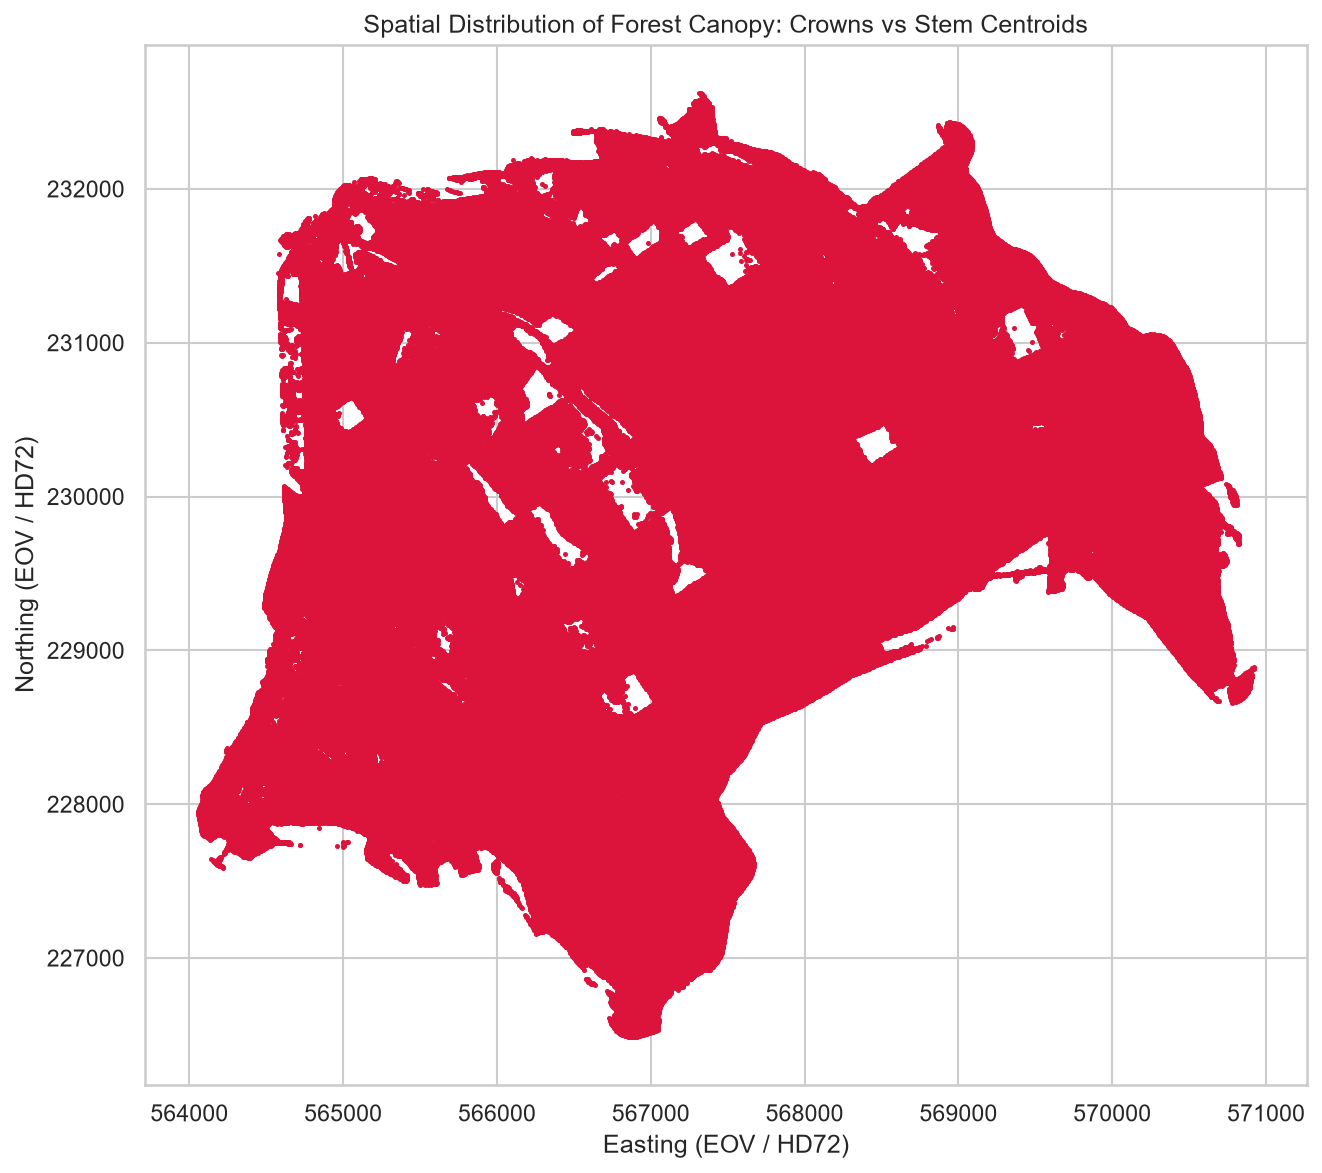

In [9]:
DATA_DIR = Path("../data/micro_soe")
points_path = DATA_DIR / "soe_rede_CrownPoints.shp"
polygons_path = DATA_DIR / "soe_rede_CrownPolygons.shp"
ortho_path = DATA_DIR / "lidar" / "ortofoto_20cm_EOV.tif"
forest_units_path = DATA_DIR / "ForestUnits.shp"

gdf_points = gpd.read_file(points_path)
gdf_polygons = gpd.read_file(polygons_path)
fu = gpd.read_file(forest_units_path)

print(f"Total Trees (Points): {len(gdf_points):,}")
print(f"Total Crowns (Polygons): {len(gdf_polygons):,}")
print(f"Points CRS: {gdf_points.crs}")
print(f"Polygons CRS: {gdf_polygons.crs}")
print(f"Forest Units Columns: {list(fu.columns)}")
print(f"Crown Polygons Columns: {list(gdf_polygons.columns)}")

display(gdf_points.isnull().sum())
display(fu.head(2))

fig, ax = plt.subplots(figsize=(10, 10))
gdf_polygons.plot(ax=ax, facecolor="none", edgecolor="forestgreen", linewidth=0.5, alpha=0.7)
gdf_points.plot(ax=ax, color="crimson", markersize=2)
ax.set_title("Spatial Distribution of Forest Canopy: Crowns vs Stem Centroids")
ax.set_xlabel("Easting (EOV / HD72)")
ax.set_ylabel("Northing (EOV / HD72)")
plt.show()

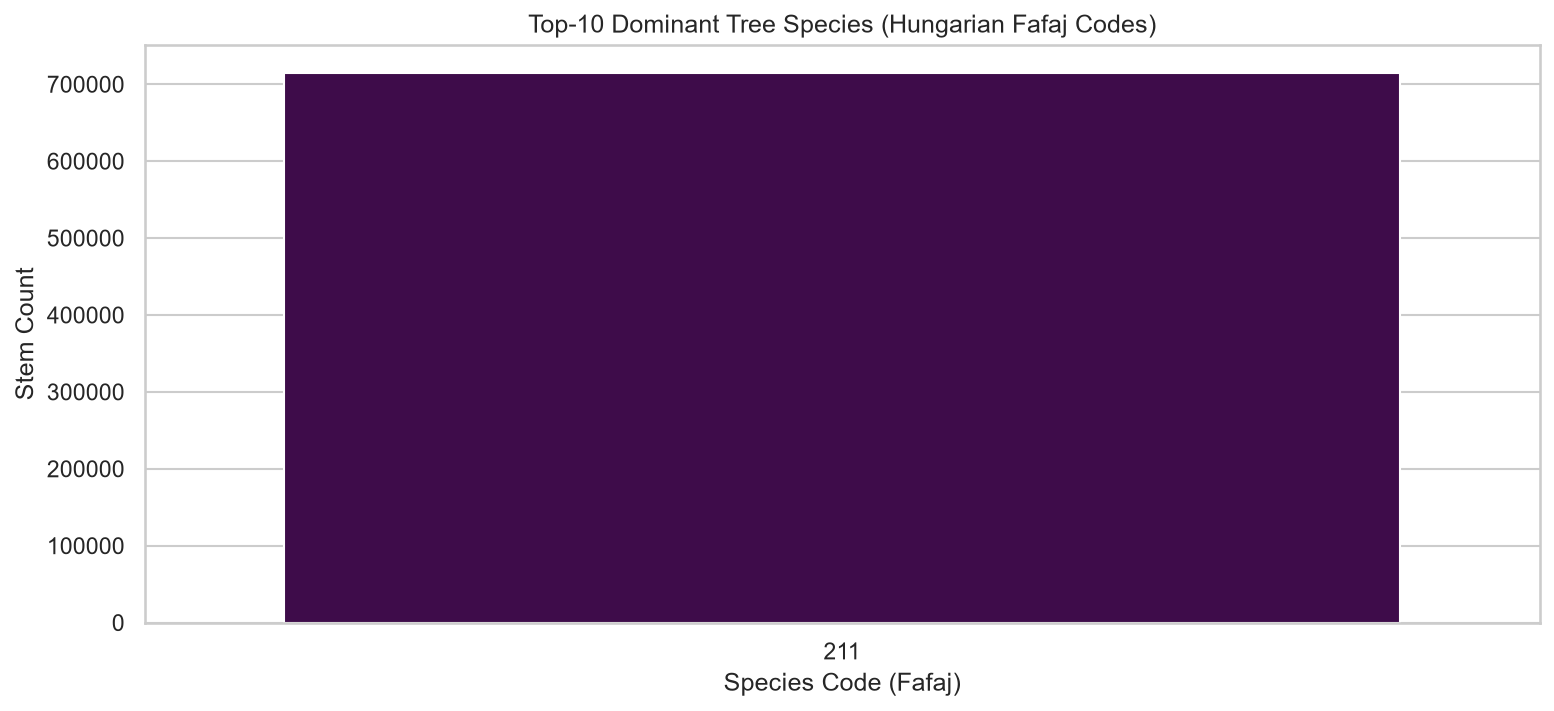

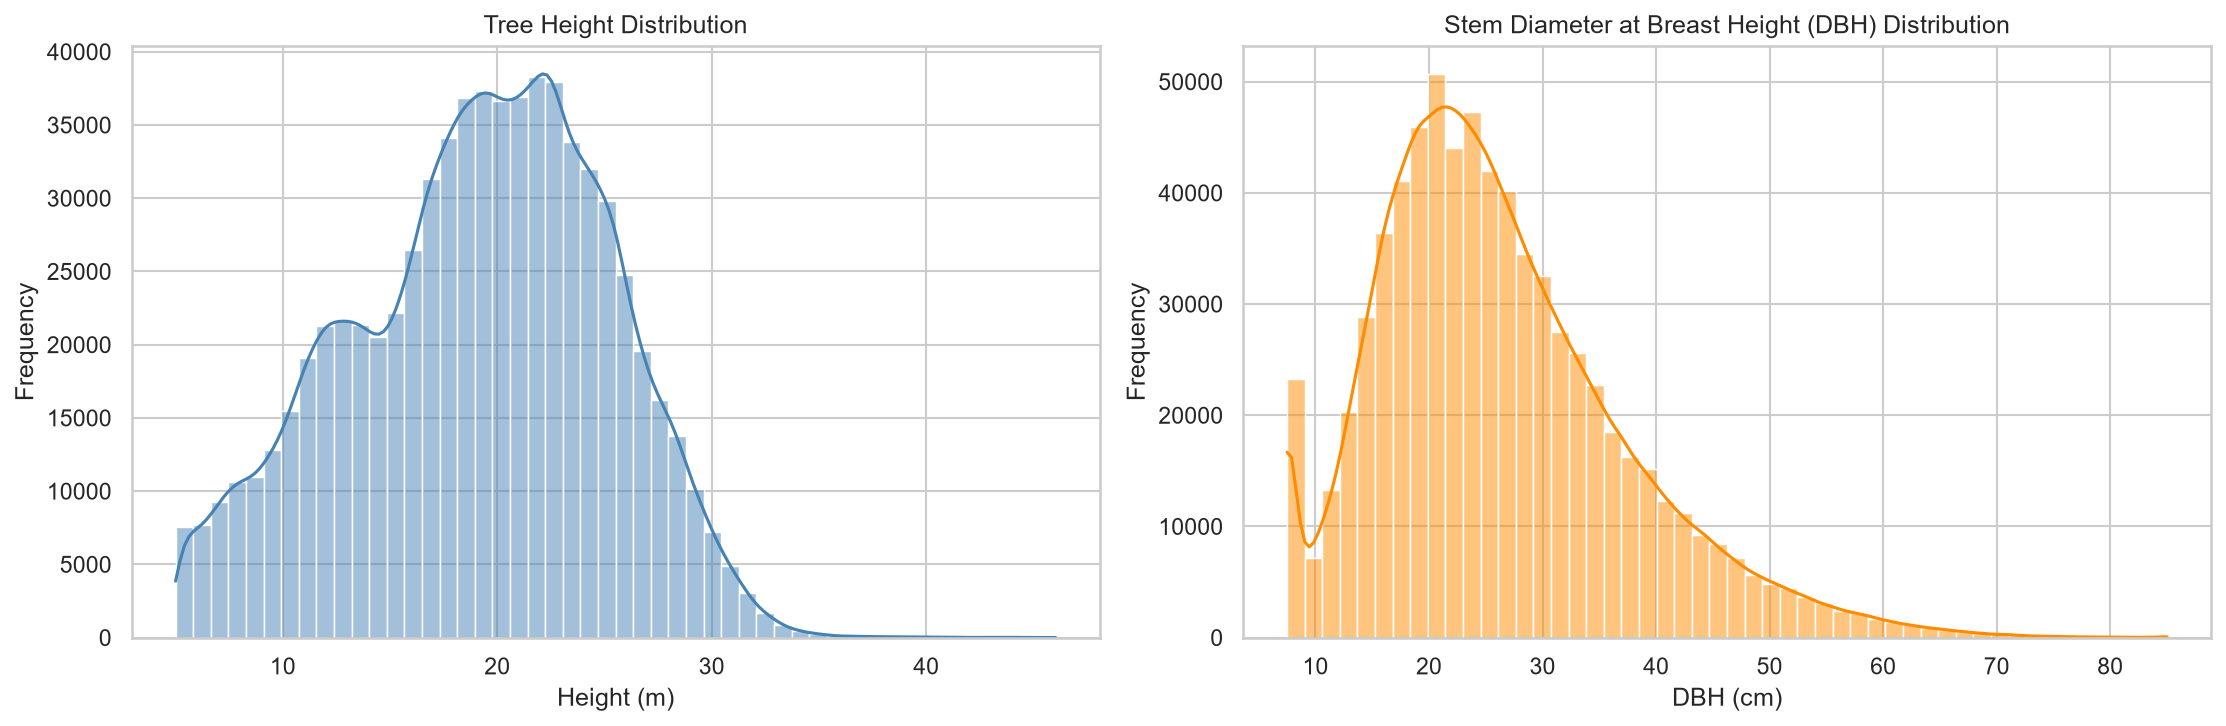

In [10]:
plt.figure(figsize=(12, 5))
species_counts = gdf_points["Fafaj"].value_counts().head(10)
sns.barplot(x=species_counts.index, y=species_counts.values, hue=species_counts.index, palette="viridis", legend=False)
plt.title("Top-10 Dominant Tree Species (Hungarian Fafaj Codes)")
plt.xlabel("Species Code (Fafaj)")
plt.ylabel("Stem Count")
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

sns.histplot(gdf_points["Magassag"], bins=50, kde=True, ax=axes[0], color="steelblue")
axes[0].set_title("Tree Height Distribution")
axes[0].set_xlabel("Height (m)")
axes[0].set_ylabel("Frequency")

sns.histplot(gdf_points["TorzsAtm"], bins=50, kde=True, ax=axes[1], color="darkorange")
axes[1].set_title("Stem Diameter at Breast Height (DBH) Distribution")
axes[1].set_xlabel("DBH (cm)")
axes[1].set_ylabel("Frequency")

plt.tight_layout()
plt.show()

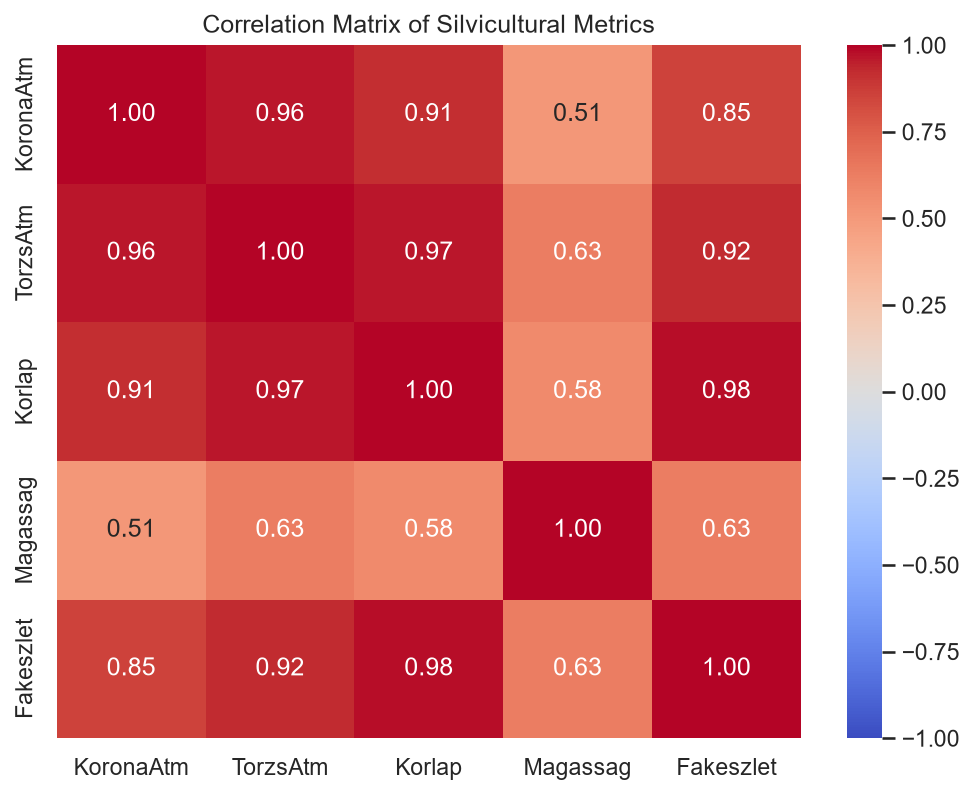

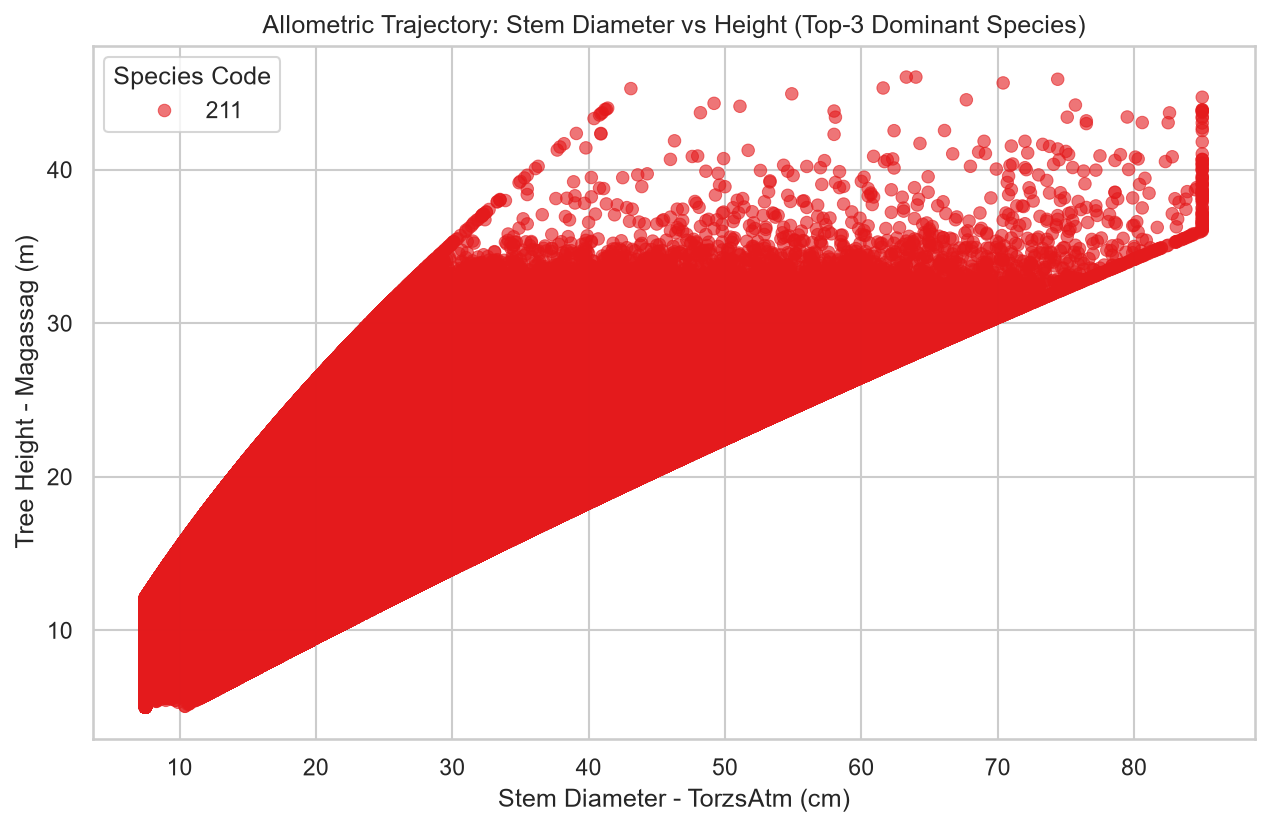

In [11]:
cols_of_interest = ["KoronaAtm", "TorzsAtm", "Korlap", "Magassag", "Fakeszlet"]
corr = gdf_points[cols_of_interest].corr()

plt.figure(figsize=(8, 6))
sns.heatmap(corr, annot=True, cmap="coolwarm", vmin=-1, vmax=1, fmt=".2f")
plt.title("Correlation Matrix of Silvicultural Metrics")
plt.show()

top_3_species = species_counts.index[:3]
subset = gdf_points[gdf_points["Fafaj"].isin(top_3_species)]

plt.figure(figsize=(10, 6))
sns.scatterplot(
    data=subset,
    x="TorzsAtm",
    y="Magassag",
    hue="Fafaj",
    alpha=0.6,
    edgecolor=None,
    palette="Set1",
)
plt.title("Allometric Trajectory: Stem Diameter vs Height (Top-3 Dominant Species)")
plt.xlabel("Stem Diameter - TorzsAtm (cm)")
plt.ylabel("Tree Height - Magassag (m)")
plt.legend(title="Species Code")
plt.show()

Orthophoto Ground Resolution: (0.19999999999999865, 0.20000000000000037)
Band Count: 3
Raster CRS: EPSG:23700
Bounding Box: BoundingBox(left=564052.9166437755, bottom=226484.76946168081, right=570930.1166437755, top=232649.96946168083)


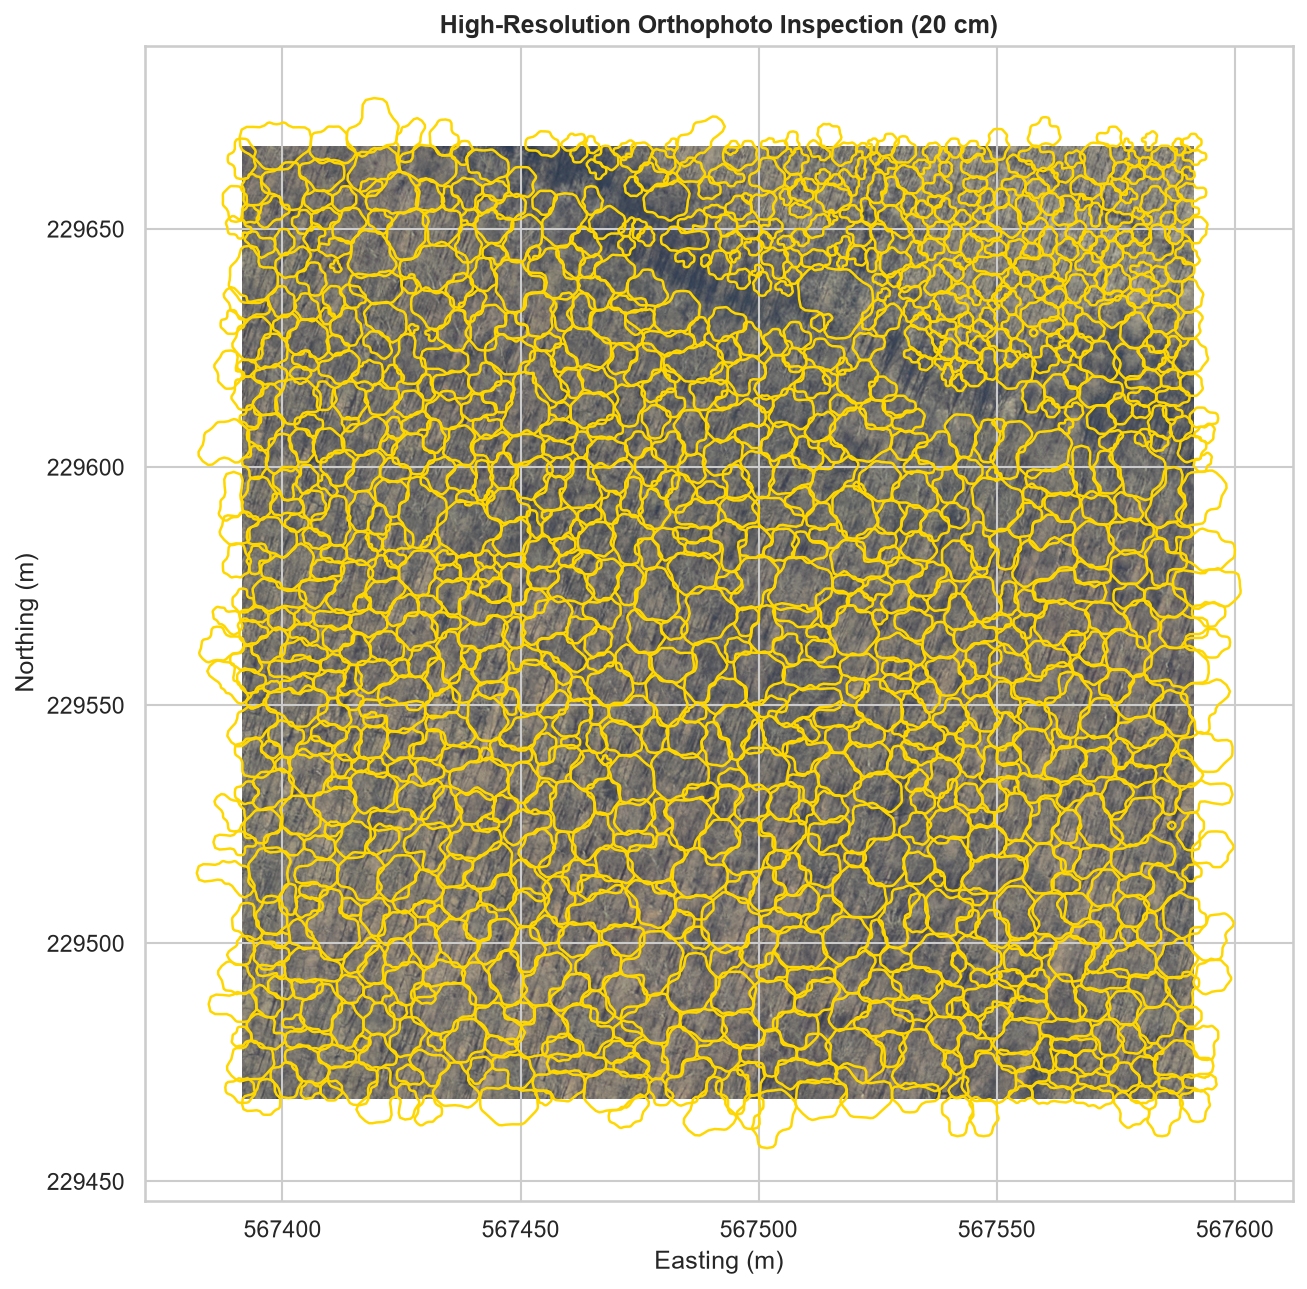

In [13]:
with rasterio.open(ortho_path) as src:
    print(f"Orthophoto Ground Resolution: {src.res}")
    print(f"Band Count: {src.count}")
    print(f"Raster CRS: {src.crs}")
    print(f"Bounding Box: {src.bounds}")

    window = rasterio.windows.Window(src.width // 2 - 500, src.height // 2 - 500, 1000, 1000)
    img_subset = src.read(window=window)
    subset_transform = src.window_transform(window)

    fig, ax = plt.subplots(figsize=(10, 10))
    show(img_subset[:3], transform=subset_transform, ax=ax, title="High-Resolution Orthophoto Inspection (20 cm)")

    minx, miny = subset_transform @ (0, window.height)
    maxx, maxy = subset_transform @ (window.width, 0)

    polygons_in_window = gdf_polygons.cx[minx:maxx, miny:maxy]
    if not polygons_in_window.empty:
        polygons_in_window.plot(ax=ax, facecolor="none", edgecolor="gold", linewidth=1.2)

    ax.set_xlabel("Easting (m)")
    ax.set_ylabel("Northing (m)")
    plt.show()

In [14]:
import geopandas as gpd

fu = gpd.read_file("../data/micro_soe/ForestUnits.shp")
print("Columns:", list(fu.columns))
print(fu.head(2))

Columns: ['RET_ID', 'EV', 'HEG_KOD', 'TAG', 'RESZLETKOD', 'TULFORMA', 'UZEMMOD', 'TERMMUTATO', 'RENDELT1', 'RENDELT2', 'RENDELT3', 'EGO_KOD', 'VEDFOK', 'REZERVTERT', 'N2000', 'FAALLT', 'FFJ_KOD', 'KOR', 'EGO_KOD_2', 'SZEKTOR', 'SZERV_KO', 'SZERV_NE', 'FAT18', 'TERULET', 'FAIZONA', 'geometry']
     RET_ID    EV  HEG_KOD  TAG RESZLETKOD  TULFORMA  UZEMMOD  TERMMUTATO  \
0  51829888  2023     4572   56          B        10        1           3   
1  51829891  2023     4572   56          C        10        1           2   

   RENDELT1  RENDELT2  ...  FFJ_KOD  KOR  EGO_KOD_2  SZEKTOR  SZERV_KO  \
0       211         0  ...      411   39          7       11     10,00   
1       211         0  ...      111   62          7       11     10,00   

            SZERV_NE  FAT18  TERULET  FAIZONA  \
0  Vértesi Erdő Zrt.      6     0.85        4   
1  Vértesi Erdő Zrt.      6     5.47        4   

                                            geometry  
0  POLYGON ((566482.98 228289.066, 566581.04 228

In [15]:
import geopandas as gpd

poly = gpd.read_file("../data/micro_soe/soe_rede_CrownPolygons.shp")
print(poly.columns)

Index(['ID', 'X', 'Y', 'KoronaTer', 'KoronaAtm', 'TorzsAtm', 'Korlap',
       'Magassag', 'Fakeszlet', 'Fafaj', 'geometry'],
      dtype='str')


In [16]:
def calculate_log_zscore(group: pd.Series) -> pd.Series:
    """Standardize log-allometric crown area to height ratios within homogeneous strata."""
    if len(group) < 30:
        return pd.Series(np.zeros(len(group)), index=group.index)
    mean = group.mean()
    std = group.std()
    return (group - mean) / (std if std > 1e-4 else 1.0)

df = pyogrio.read_dataframe(Path("D:/Réde/rede_crowns_enriched.gpkg"), read_geometry=False)
df_clean = df[(df["FFJ_KOD"] > 0) & (df["chm_max"] >= 5.0)].copy()

df_clean["age_class"] = (df_clean["KOR"] // 10) * 10
df_clean["log_crown_ratio"] = np.log(df_clean["KoronaTer"] + 1e-4) - np.log(df_clean["chm_max"])

df_clean["z_crown"] = df_clean.groupby(["FFJ_KOD", "age_class"])["log_crown_ratio"].transform(calculate_log_zscore)
df_clean["is_stressed"] = df_clean["z_crown"] <= -1.65

species_mapping = {
    111: "Pedunculate oak (111)",
    211: "Turkey oak (211)",
    411: "Hornbeam (411)",
    831: "Linden (831)",
}
df_clean["Species_Name"] = df_clean["FFJ_KOD"].map(species_mapping).fillna("Other")

stressed_count = int(df_clean["is_stressed"].sum())
stressed_pct = float(df_clean["is_stressed"].mean() * 100)

print(f"Filtered valid crowns: {len(df_clean):,}")
print(f"Identified symptomatic / stressed crowns: {stressed_count:,} ({stressed_pct:.2f}%)")

Filtered valid crowns: 643,678
Identified symptomatic / stressed crowns: 40,036 (6.22%)


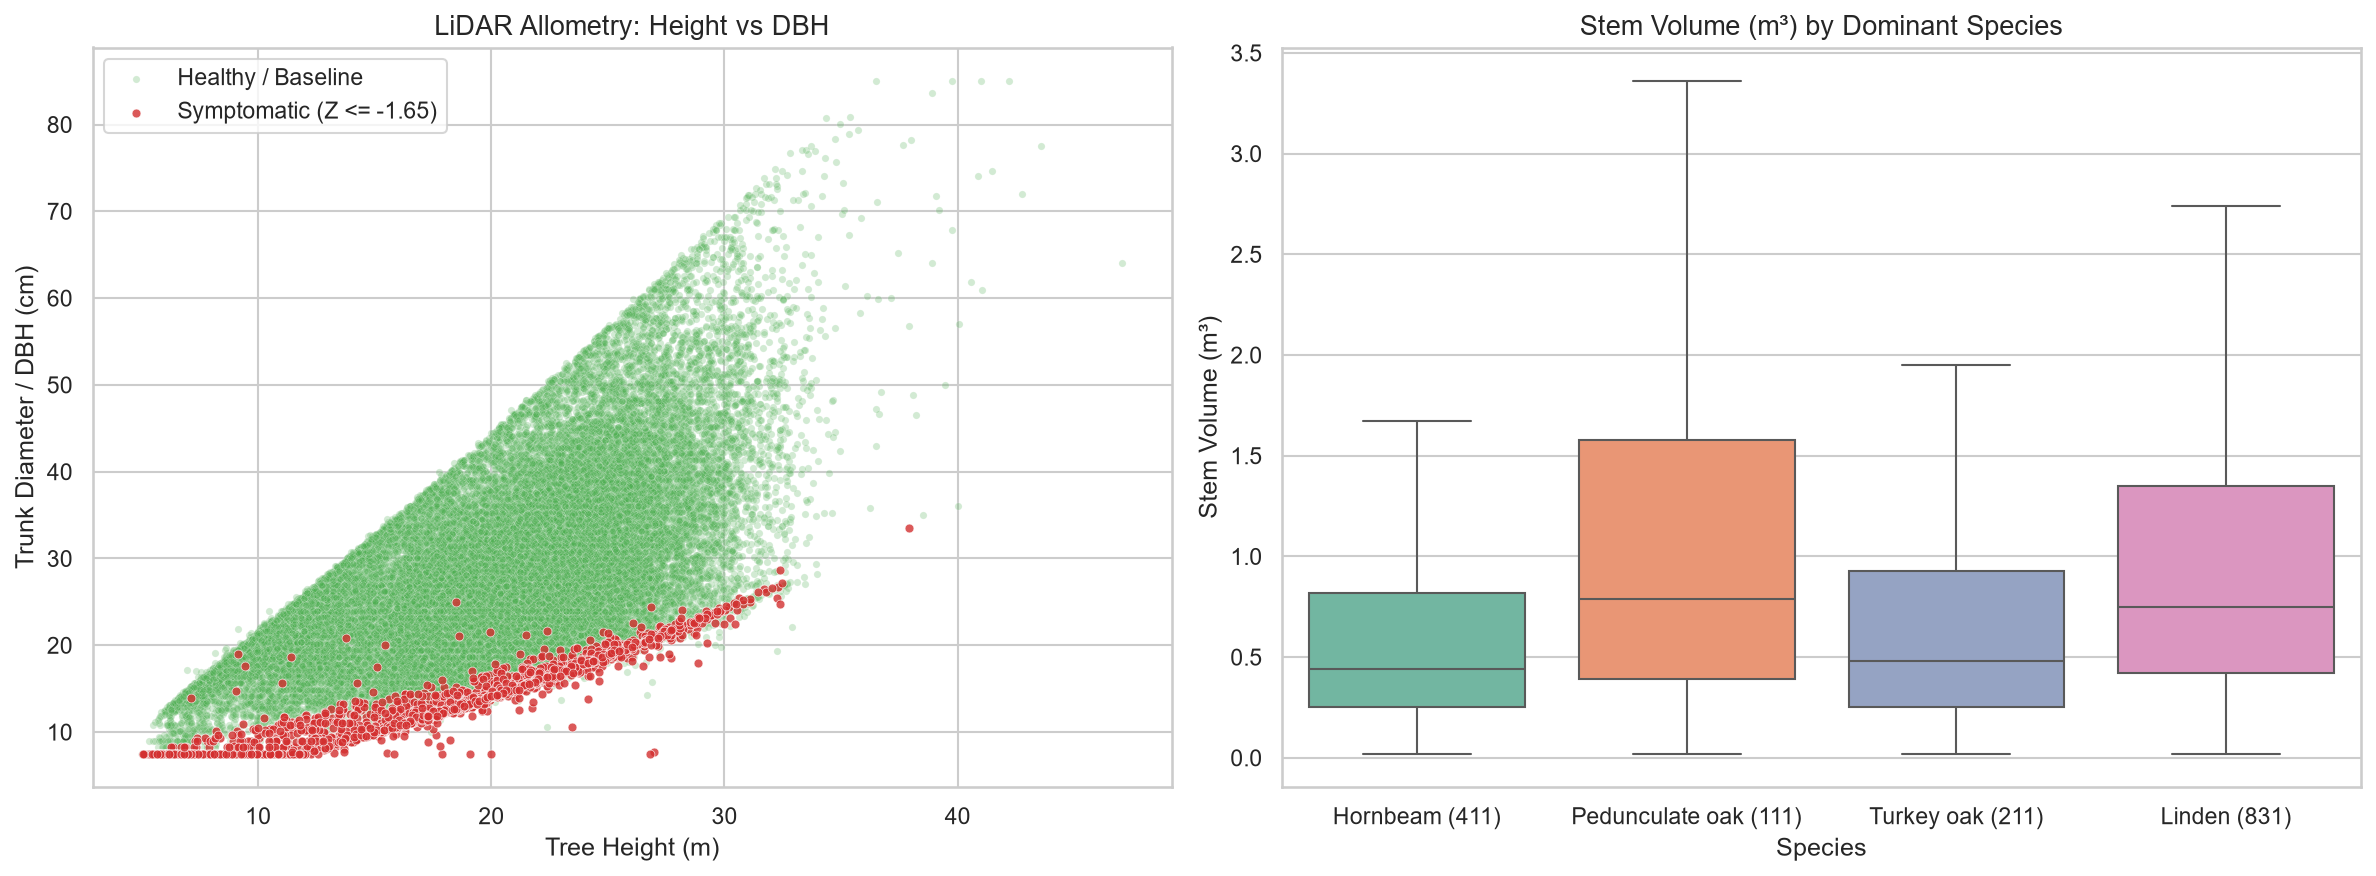

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

sample_df = df_clean.sample(min(40000, len(df_clean)), random_state=42)

sns.scatterplot(
    data=sample_df[~sample_df["is_stressed"]],
    x="chm_max",
    y="TorzsAtm",
    color="#4caf50",
    alpha=0.25,
    s=12,
    label="Healthy / Baseline",
    ax=axes[0],
)
sns.scatterplot(
    data=sample_df[sample_df["is_stressed"]],
    x="chm_max",
    y="TorzsAtm",
    color="#d32f2f",
    alpha=0.8,
    s=18,
    label="Symptomatic (Z <= -1.65)",
    ax=axes[0],
)

axes[0].set_title("LiDAR Allometry: Height vs DBH", fontsize=13)
axes[0].set_xlabel("Tree Height (m)")
axes[0].set_ylabel("Trunk Diameter / DBH (cm)")
axes[0].legend(loc="upper left")

top_species = [111, 211, 411, 831]
df_top = df_clean[df_clean["FFJ_KOD"].isin(top_species)].copy()

sns.boxplot(
    data=df_top,
    x="Species_Name",
    y="Fakeszlet",
    hue="Species_Name",
    legend=False,
    showfliers=False,
    ax=axes[1],
    palette="Set2",
)
axes[1].set_title("Stem Volume (m³) by Dominant Species", fontsize=13)
axes[1].set_xlabel("Species")
axes[1].set_ylabel("Stem Volume (m³)")

plt.tight_layout()
plt.savefig(Path("../data/03_results/maps") / "allometry_stock_audit.png", dpi=300)
plt.show()

--- Stress Distribution by Species ---


,total,stressed,pct_stressed
Species_Name,,,
Turkey oak (211),447637,28547,6.377266
Other,79903,4279,5.355243
Hornbeam (411),65636,4251,6.476629
Linden (831),26412,1510,5.717098
Pedunculate oak (111),24090,1449,6.014944


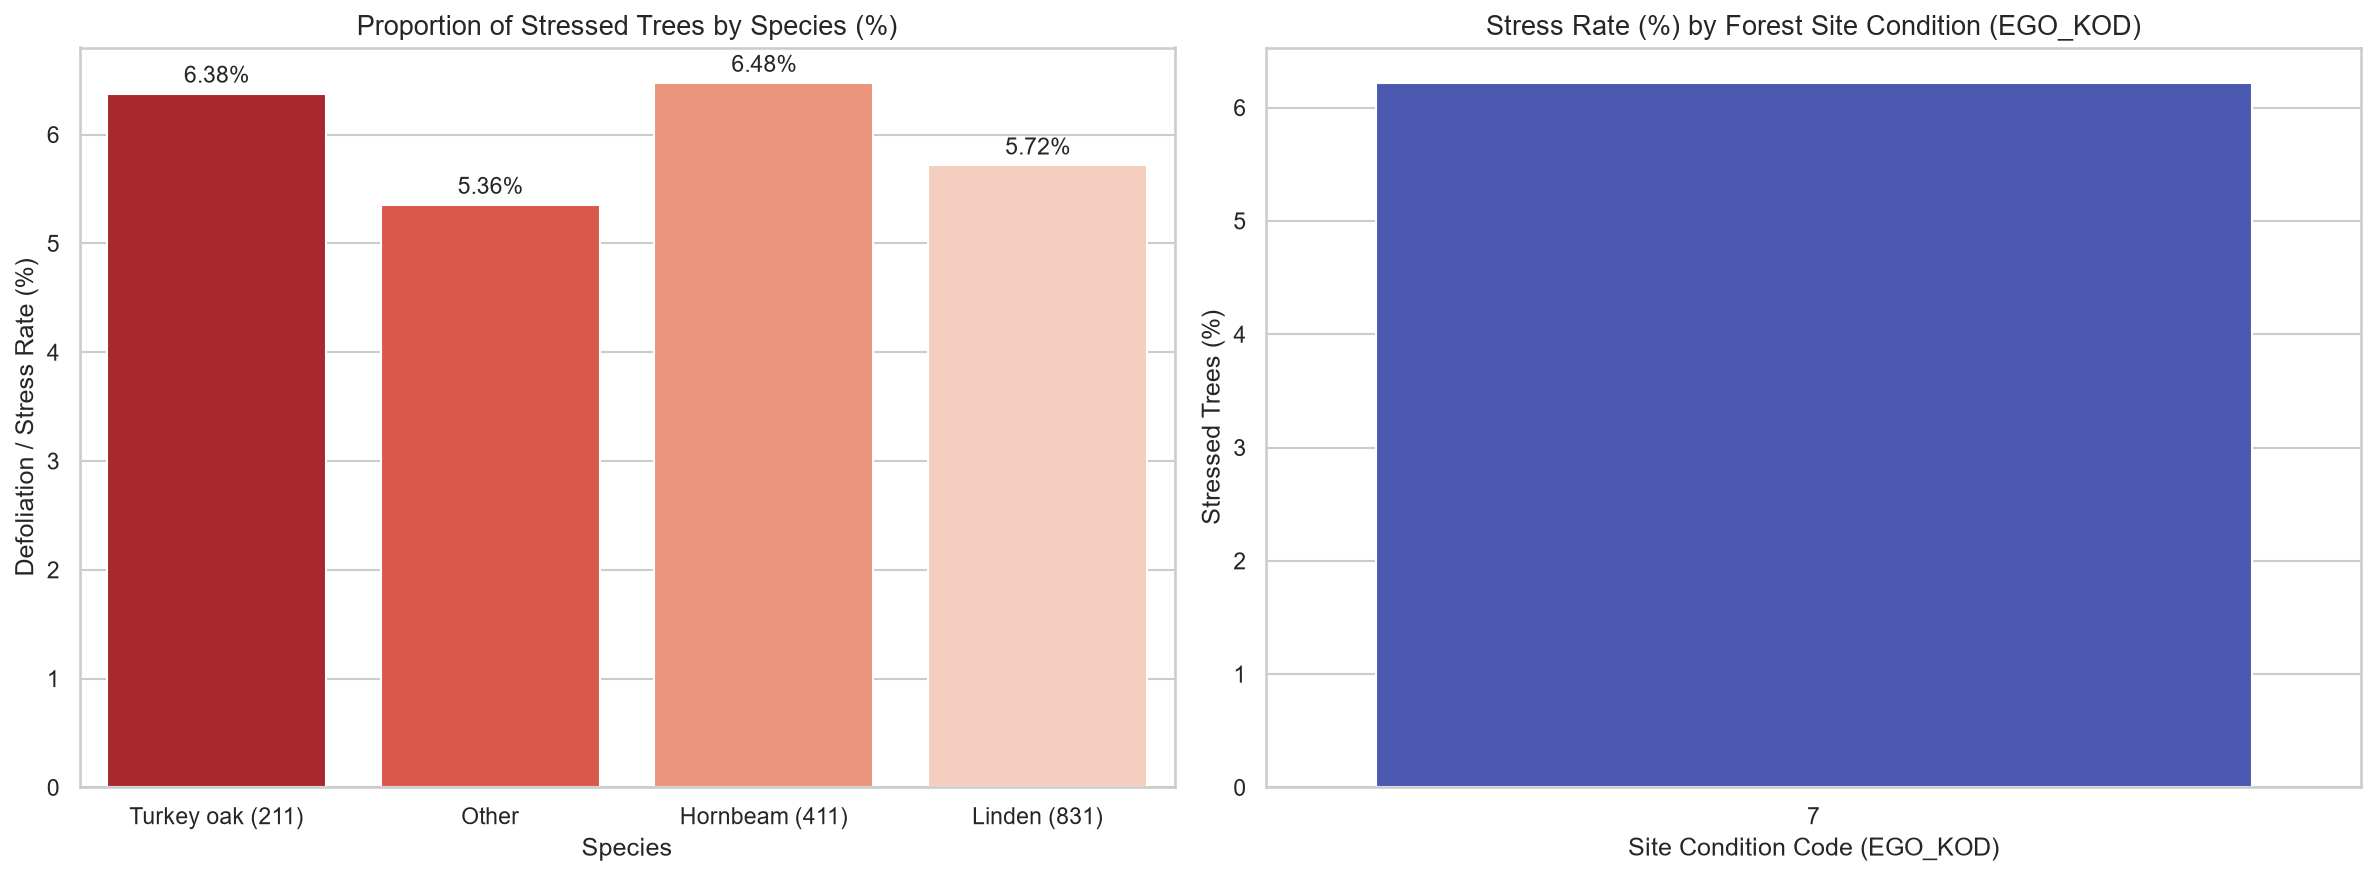

In [19]:
species_stress = (
    df_clean.groupby("Species_Name")["is_stressed"]
    .agg(
        total="count",
        stressed="sum",
        pct_stressed=lambda x: x.mean() * 100,
    )
    .sort_values(by="total", ascending=False)
)

print("--- Stress Distribution by Species ---")
display(species_stress)

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

top_species_stress = species_stress.head(4).reset_index()
sns.barplot(
    data=top_species_stress,
    x="Species_Name",
    y="pct_stressed",
    hue="Species_Name",
    legend=False,
    palette="Reds_r",
    ax=axes[0],
)
axes[0].set_title("Proportion of Stressed Trees by Species (%)", fontsize=13)
axes[0].set_xlabel("Species")
axes[0].set_ylabel("Defoliation / Stress Rate (%)")

for p in axes[0].patches:
    axes[0].annotate(
        f"{p.get_height():.2f}%",
        (p.get_x() + p.get_width() / 2.0, p.get_height() + 0.1),
        ha="center",
        fontsize=11,
    )

ego_stress = (
    (df_clean.groupby("EGO_KOD")["is_stressed"].mean() * 100)
    .loc[lambda s: s.index > 0]
    .reset_index()
)

sns.barplot(
    data=ego_stress,
    x="EGO_KOD",
    y="is_stressed",
    hue="EGO_KOD",
    legend=False,
    palette="coolwarm",
    ax=axes[1],
)
axes[1].set_title("Stress Rate (%) by Forest Site Condition (EGO_KOD)", fontsize=13)
axes[1].set_xlabel("Site Condition Code (EGO_KOD)")
axes[1].set_ylabel("Stressed Trees (%)")

plt.tight_layout()
plt.savefig(Path("../data/03_results/maps") / "edaphic_species_stress.png", dpi=300)
plt.show()

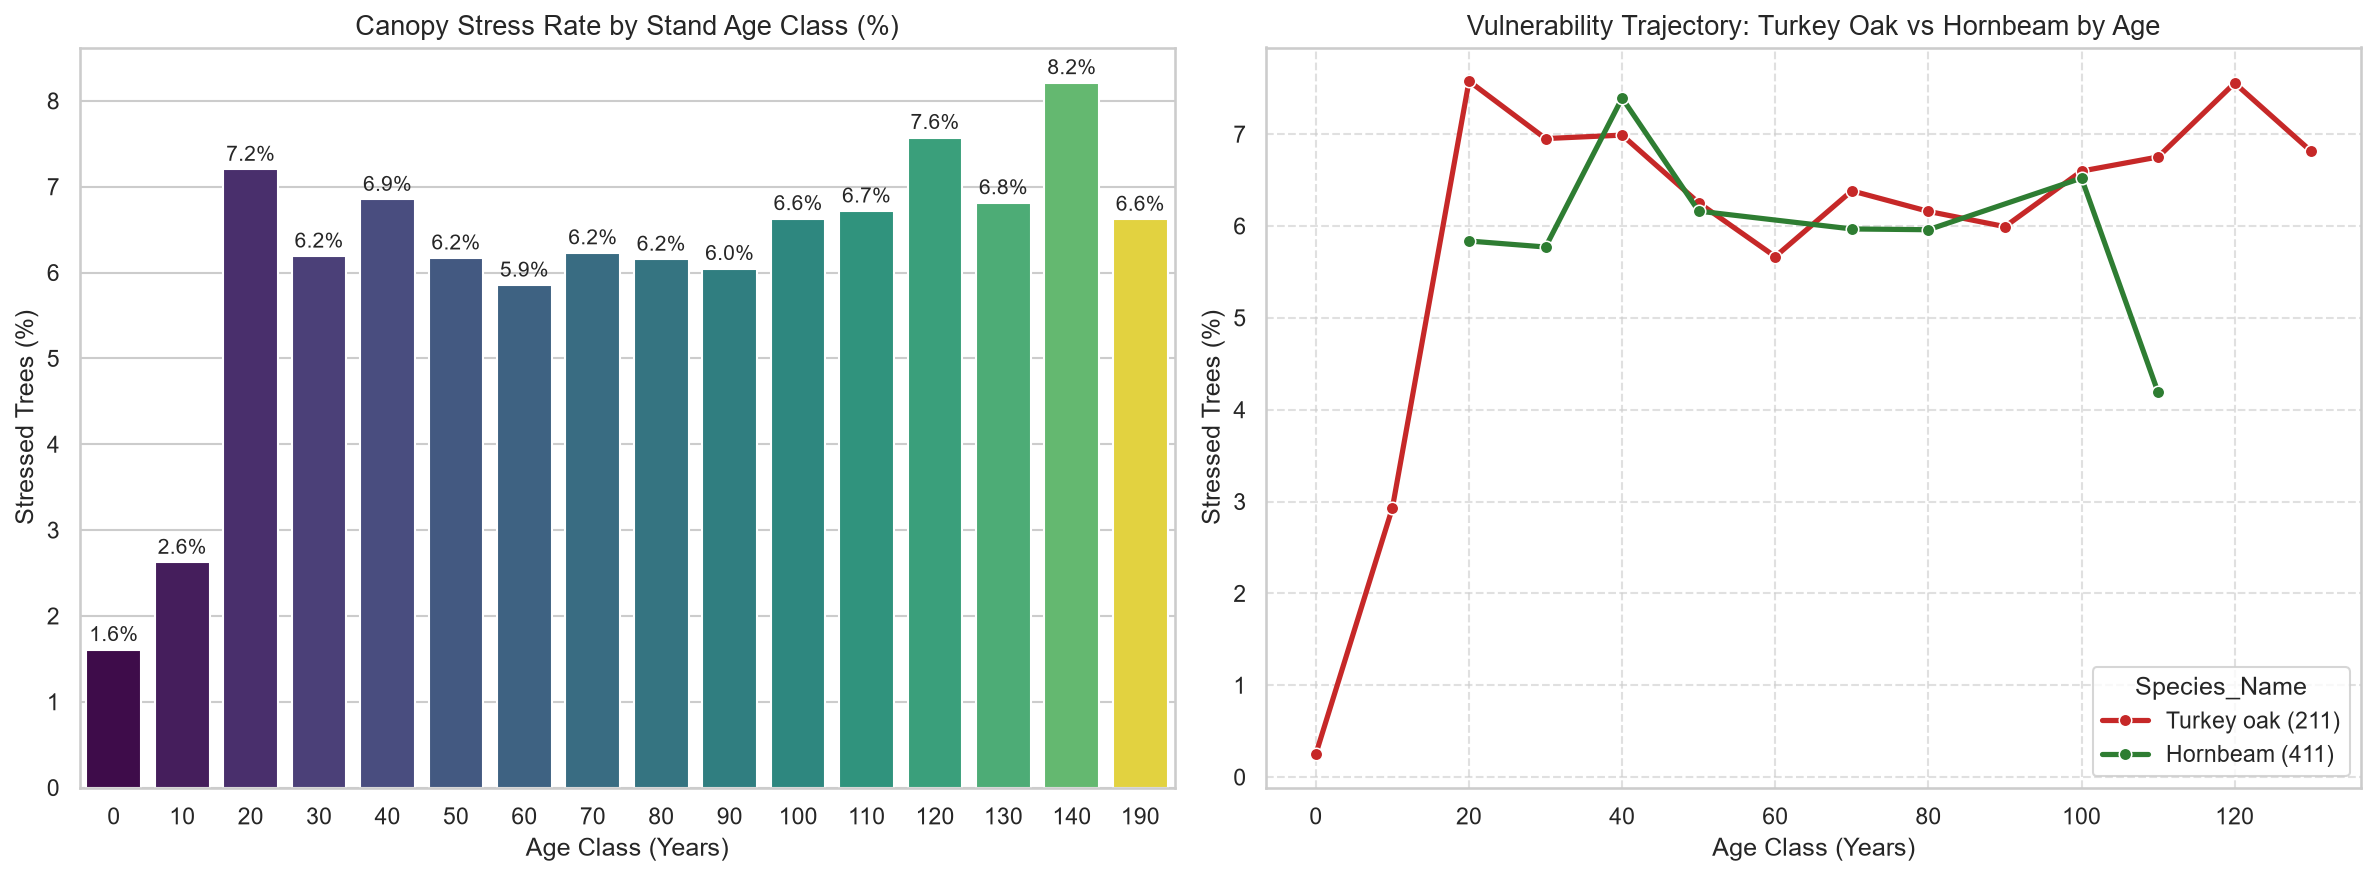

In [20]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

age_stress = (
    df_clean.groupby("age_class")["is_stressed"]
    .agg(
        total="count",
        pct_stressed=lambda x: x.mean() * 100,
    )
    .reset_index()
)
age_stress = age_stress[age_stress["total"] >= 500]

sns.barplot(
    data=age_stress,
    x="age_class",
    y="pct_stressed",
    hue="age_class",
    legend=False,
    palette="viridis",
    ax=axes[0],
)
axes[0].set_title("Canopy Stress Rate by Stand Age Class (%)", fontsize=13)
axes[0].set_xlabel("Age Class (Years)")
axes[0].set_ylabel("Stressed Trees (%)")

for p in axes[0].patches:
    axes[0].annotate(
        f"{p.get_height():.1f}%",
        (p.get_x() + p.get_width() / 2.0, p.get_height() + 0.1),
        ha="center",
        fontsize=10,
    )

species_age = (
    df_clean[df_clean["FFJ_KOD"].isin([211, 411])]
    .groupby(["age_class", "Species_Name"])["is_stressed"]
    .mean()
    .reset_index()
)
species_age["is_stressed"] *= 100
species_age = species_age[species_age["age_class"].isin(age_stress["age_class"])]

sns.lineplot(
    data=species_age,
    x="age_class",
    y="is_stressed",
    hue="Species_Name",
    marker="o",
    linewidth=2.5,
    palette={"Turkey oak (211)": "#c62828", "Hornbeam (411)": "#2e7d32"},
    ax=axes[1],
)
axes[1].set_title("Vulnerability Trajectory: Turkey Oak vs Hornbeam by Age", fontsize=13)
axes[1].set_xlabel("Age Class (Years)")
axes[1].set_ylabel("Stressed Trees (%)")
axes[1].grid(True, linestyle="--", alpha=0.6)

plt.tight_layout()
plt.savefig(Path("../data/03_results/maps") / "age_class_dynamics.png", dpi=300)
plt.show()

In [21]:
stand_stress = (
    df_clean.groupby(["TAG", "RESZLETKOD"])
    .agg(
        total_crowns=("is_stressed", "count"),
        stressed_crowns=("is_stressed", "sum"),
        stress_pct=("is_stressed", lambda x: x.mean() * 100),
    )
    .reset_index()
)

gdf_stands = gpd.read_file(Path("D:/Réde/ForestUnits.shp"))
gdf_result = gdf_stands.merge(stand_stress, on=["TAG", "RESZLETKOD"], how="left")

gdf_result["stress_pct"] = gdf_result["stress_pct"].fillna(0.0)
gdf_result["stressed_crowns"] = gdf_result["stressed_crowns"].fillna(0)
gdf_result["total_crowns"] = gdf_result["total_crowns"].fillna(0)

gdf_result.to_file(Path("D:/Réde/ForestUnits_Drought_Risk.gpkg"), driver="GPKG")
print(f"Compartment stress layer successfully saved: {Path("D:/Réde/ForestUnits_Drought_Risk.gpkg")}")

top_stands = gdf_result[gdf_result["total_crowns"] >= 100].nlargest(
    5, "stress_pct"
)[["TAG", "RESZLETKOD", "KOR", "TERULET", "total_crowns", "stress_pct"]]

print("\n=== TOP 5 IMPACTED FOREST COMPARTMENTS IN RÉDE ===")
for _, r in top_stands.iterrows():
    print(
        f"Compartment {r['TAG']}/{r['RESZLETKOD']} | "
        f"Age: {int(r['KOR'])} yrs | "
        f"Area: {r['TERULET']:.2f} ha | "
        f"Crown Count: {int(r['total_crowns'])} | "
        f"Stress Rate: {r['stress_pct']:.2f}%"
    )

Compartment stress layer successfully saved: D:\Réde\ForestUnits_Drought_Risk.gpkg

=== TOP 5 IMPACTED FOREST COMPARTMENTS IN RÉDE ===
Compartment 52/E | Age: 21 yrs | Area: 0.82 ha | Crown Count: 227 | Stress Rate: 49.34%
Compartment 9/B | Age: 26 yrs | Area: 3.18 ha | Crown Count: 1209 | Stress Rate: 31.27%
Compartment 37/C 1 | Age: 22 yrs | Area: 1.98 ha | Crown Count: 472 | Stress Rate: 29.24%
Compartment 35/C 1 | Age: 42 yrs | Area: 7.45 ha | Crown Count: 3409 | Stress Rate: 21.65%
Compartment 20/A | Age: 24 yrs | Area: 3.99 ha | Crown Count: 1316 | Stress Rate: 21.28%
